# 08 - Little Lessons

Registered passages ? saved storyboard ? code validation ? step cards ? narration ? video ? human scene review ? approved library. The separate 39-case dataset has **draft intent labels**; routing and source-fidelity scores never approve media. Logic lives in `evals/lessons_eval.py` and `nestling/lessons/`. Re-executing this notebook makes no paid or network calls.

In [1]:
from evals import lessons_eval
from nestling.lessons import library

lesson = library.get("cord_care")
board = lesson["storyboard"]
print({"lesson_id": board["lesson_id"], "version": board["version"], "steps": len(board["scenes"]), "sources": board["sources"]})
print(lessons_eval.review_summary(board, lesson["review"]))

{'lesson_id': 'cord_care', 'version': 4, 'steps': 4, 'sources': ['MOHFW-ANC', 'WHO-POSTNATAL']}
{'status': 'reviewed', 'n_scenes': 4, 'n_reviewed': 4, 'pass_rate': 1.0, 'scenes': [{'step_no': 1, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in chat on 2026-11-01.'}, {'step_no': 2, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in chat on 2026-11-01.'}, {'step_no': 3, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in chat on 2026-11-01.'}, {'step_no': 4, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in chat on 2026-11-01.'}], 'approved': True}


The storyboard is loaded from the saved build. The latest saved summary below distinguishes live measurements from offline inventory; real render logs supply incremental costs and durations. Missing logs remain unknown. The separately authorized live routing and source-fidelity evaluation uses `uv run python -m evals.lessons_eval --live --upload` and its own cumulative ?20 ledger. Every label remains draft until human review.

In [2]:
result = lessons_eval.latest()
print({k: v for k, v in result.items() if k not in ("cases", "lessons")})
for item in result["lessons"]:
    print(item["lesson_id"], item["review"]["status"], item["fidelity"]["status"], item["render"])
    if item["fidelity"].get("faithful") is False:
        print("Judge findings for human review:", item["fidelity"]["explanation"])


{'dataset': 'nestling-lessons-v1', 'label_status': 'draft; pending owner review', 'n_cases': 39, 'routing_accuracy': 1.0, 'danger_escalation_accuracy': 1.0, 'n_errors': 0, 'step_fidelity': 0.8, 'n_storyboards_judged': 5, 'judge': 'Qwen/Qwen3-235B-A22B-Instruct-2507', 'judge_prompt': 'evals\\lessons_judge_prompt.md', 'total_live_cost_inr': 1.6711, 'live': True, 'experiment': 'nestling-lessons-f15c178e', 'budget_cap_inr': 20.0, 'budget_accounted_inr': 1.6711, 'budget_ledger': 'evals/results/lessons_v1_spend.json', 'inventory_note': 'Owner-approved current scene reviews and cached review-date renders refreshed; routing and fidelity judgments unchanged.', 'version_history': [{'lesson_id': 'cord_care', 'version': 2, 'review': {'status': 'reviewed', 'n_scenes': 4, 'n_reviewed': 4, 'pass_rate': 1.0, 'scenes': [{'step_no': 1, 'passed': True, 'notes': 'Approved by the owner in chat for this storyboard version.'}, {'step_no': 2, 'passed': True, 'notes': 'Approved by the owner in chat for this st

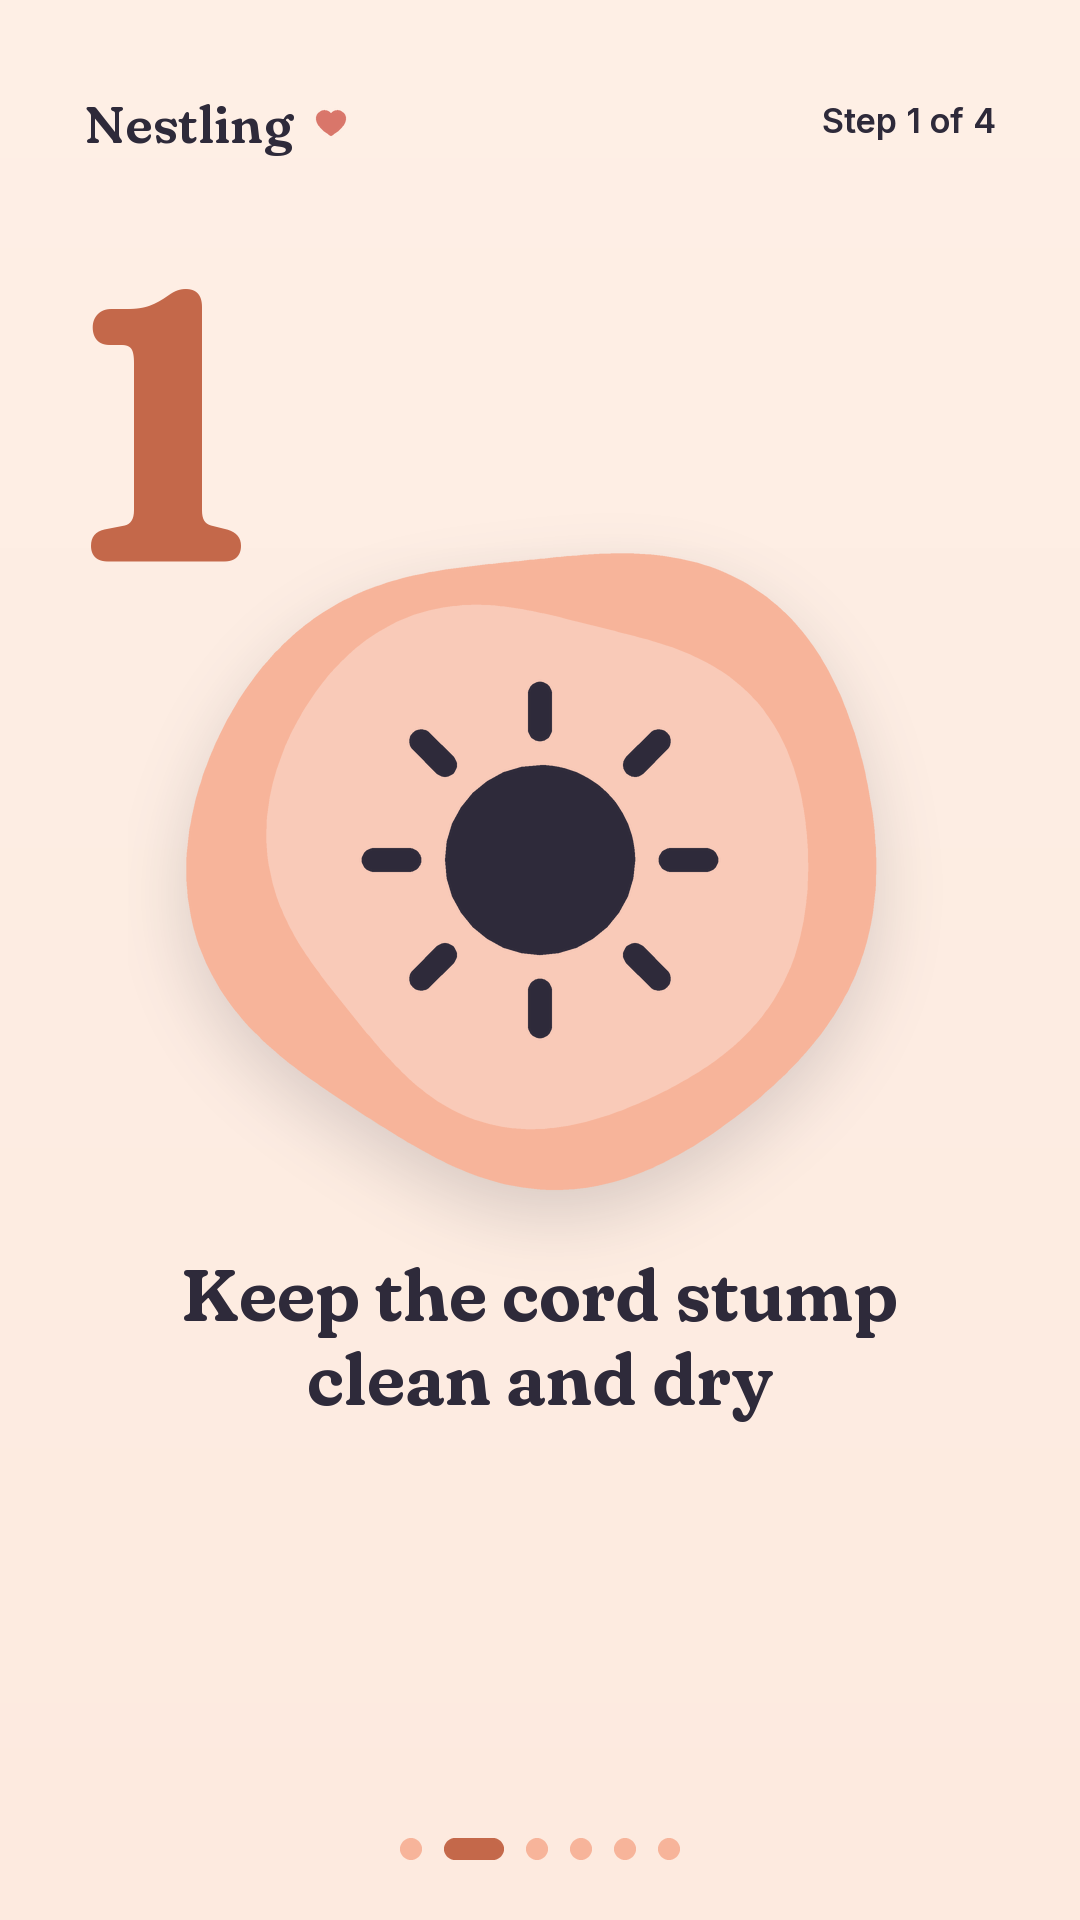

In [3]:
from IPython.display import display, Image

display(Image(filename=str(lesson["folder"] / "renders" / "card_2.png"), width=270))